# Proyecto Vision con YOLO26

Demo local antes de desplegar a Cloud Run.

Version anterior del curso: **YOLOv3** via `cvlib` (motor OpenCV DNN, 237 MB de pesos).
Version actual: **YOLO26** via `ultralytics` (motor PyTorch, 5 MB de pesos).

Instalacion:
```
uv sync
```

Y para abrir este notebook: `uv run jupyter notebook server.ipynb`

In [1]:
import os
import tempfile

# Ultralytics escribe un settings.yaml al importarse. Usamos el temporal del
# sistema en lugar de "/tmp" a secas, que no existe en Windows.
os.environ.setdefault(
    'YOLO_CONFIG_DIR', os.path.join(tempfile.gettempdir(), 'ultralytics')
)

from IPython.display import Image, display


Displaying image: apples.jpg


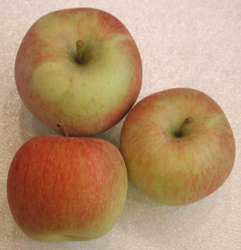


Displaying image: clock.jpg


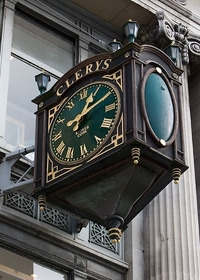


Displaying image: oranges.jpg


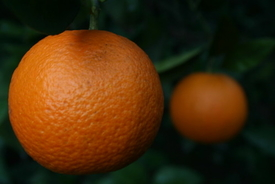


Displaying image: car.jpg


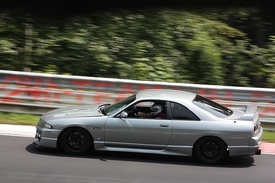

In [2]:
# Some example images
image_files = [
    'apples.jpg',
    'clock.jpg',
    'oranges.jpg',
    'car.jpg'
]

for image_file in image_files:
    print(f"\nDisplaying image: {image_file}")
    display(Image(filename=f"images/{image_file}"))

## 1. Cargar el modelo

La primera vez, `ultralytics` descarga los pesos desde los releases de GitHub.
Fijate en el tamano: son **~5 MB** contra los **237 MB** de `yolov3.weights`.

In [3]:
import cv2
from ultralytics import YOLO

_models = {}

def get_model(name):
    """Cachea el modelo para no reconstruir la red en cada llamada."""
    if name not in _models:
        print(f"Cargando {name}...")
        _models[name] = YOLO(f"{name}.pt")
    return _models[name]


model = get_model("yolo26n")
print(model)

Cargando yolo26n...
YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, 

In [4]:
# Cuanto peso en disco ocupa realmente
import glob
for f in sorted(glob.glob("*.pt")):
    print(f"{f:16s} {os.path.getsize(f) / 1e6:6.1f} MB")

yolo26n.pt          5.5 MB


## 2. Funcion de deteccion

Misma firma que la version con `cvlib`, para que la clase pueda comparar linea por linea.
Lo que cambia es el interior: `model.predict()` en lugar de `cv.detect_common_objects()`,
y `results[0].plot()` en lugar de `draw_bbox()`.

In [5]:
# cv2.imwrite NO lanza excepcion si la carpeta no existe: devuelve False y el
# error aparece despues, al intentar mostrar un archivo que nunca se escribio.
os.makedirs('images_with_boxes', exist_ok=True)


def detect_and_draw_box(filename, model="yolo26n", confidence=0.5, device="cpu"):
    """Detects common objects on an image and creates a new image with bounding boxes.

    Args:
        filename (str): Filename of the image.
        model (str): Either "yolo26n" or "yolo26s". Defaults to "yolo26n".
        confidence (float): Minimum confidence to keep a detection. Defaults to 0.5.
        device (str): "cpu", "mps" (Apple) o "cuda" (NVIDIA). Defaults to "cpu"
            para que el resultado sea comparable entre todas las maquinas.
    """
    img_filepath = f'images/{filename}'

    results = get_model(model).predict(img_filepath, conf=confidence,
                                       device=device, verbose=False)
    result = results[0]

    # Imagen anotada (BGR) lista para guardar
    output_image = result.plot()
    if not cv2.imwrite(f'images_with_boxes/{filename}', output_image):
        raise IOError(f"No se pudo escribir images_with_boxes/{filename}")

    # Que detecto y con cuanta confianza
    if len(result.boxes) == 0:
        print("Sin detecciones sobre el umbral.")
    for box in result.boxes:
        label = result.names[int(box.cls)]
        print(f"Detected object: {label} with confidence level of {float(box.conf):.4f}")

    display(Image(f'images_with_boxes/{filename}'))

Detected object: apple with confidence level of 0.8291
Detected object: orange with confidence level of 0.7598
Detected object: apple with confidence level of 0.5617


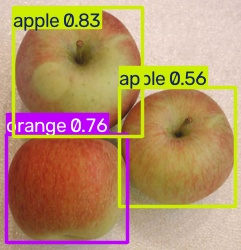

Detected object: clock with confidence level of 0.8260


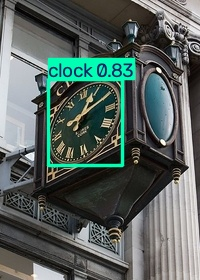

Detected object: orange with confidence level of 0.8864
Detected object: orange with confidence level of 0.8018


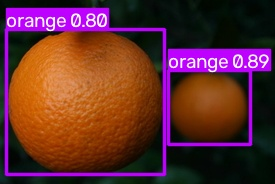

Detected object: car with confidence level of 0.9470


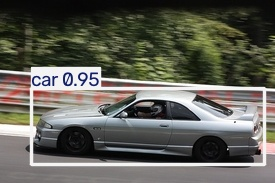

In [6]:
for image_file in image_files:
    detect_and_draw_box(image_file)

### Efecto del umbral de confianza

Mismo ejercicio que en la version YOLOv3: subir el umbral descarta detecciones dudosas.

Sin detecciones sobre el umbral.


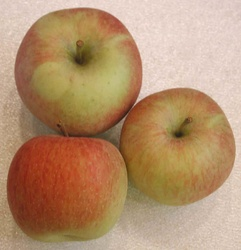

Sin detecciones sobre el umbral.


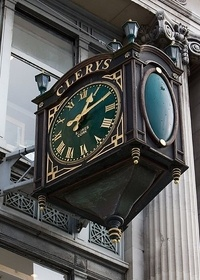

Sin detecciones sobre el umbral.


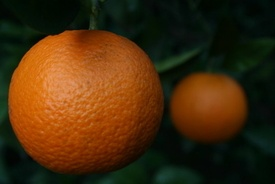

Detected object: car with confidence level of 0.9470


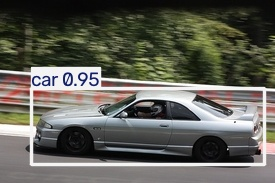

In [7]:
for image_file in image_files:
    detect_and_draw_box(image_file, confidence=0.9)

Detected object: orange with confidence level of 0.8516
Detected object: orange with confidence level of 0.7883
Detected object: orange with confidence level of 0.5089


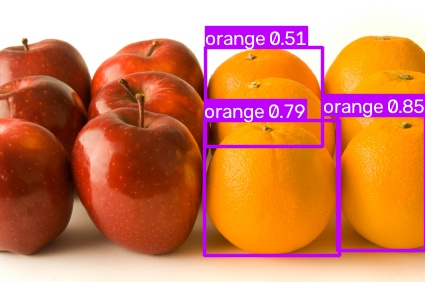

In [8]:
detect_and_draw_box("fruits.jpg")

Detected object: orange with confidence level of 0.8516
Detected object: orange with confidence level of 0.7883
Detected object: orange with confidence level of 0.5089
Detected object: orange with confidence level of 0.4182
Detected object: orange with confidence level of 0.3867
Detected object: apple with confidence level of 0.3406


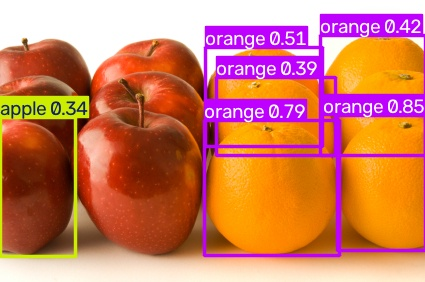

In [9]:
detect_and_draw_box("fruits.jpg", confidence=0.3)

## 3. Donde corre la inferencia: tu hardware vs produccion

PyTorch puede usar aceleradores, a diferencia de YOLOv3 sobre OpenCV DNN que
solo hacia CPU. Segun la maquina de cada uno:

- **MPS** — la GPU integrada de los chips M de Apple (macOS)
- **CUDA** — GPU NVIDIA (Windows / Linux)
- **CPU** — siempre disponible, y es lo unico que hay en Cloud Run

Las celdas de abajo detectan que tienes y miden solo eso, asi que funcionan
igual en macOS, Windows y Linux.

Buen momento para aclarar una confusion tipica: "no tengo GPU" casi siempre
significa "no tengo NVIDIA/CUDA". Un Mac con chip M tambien tiene GPU.

In [10]:
import torch, platform


def best_device():
    """Devuelve el mejor acelerador disponible en ESTA maquina."""
    if torch.backends.mps.is_available():
        return "mps"      # GPU integrada de Apple Silicon
    if torch.cuda.is_available():
        return "cuda"     # GPU NVIDIA
    return "cpu"


print(f"Sistema:         {platform.system()} / {platform.machine()}")
print(f"PyTorch:         {torch.__version__}")
print(f"MPS (Apple):     {torch.backends.mps.is_available()}")
print(f"CUDA (NVIDIA):   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:             {torch.cuda.get_device_name(0)}")
print(f"--> se usara:    {best_device()}")

Sistema:         Darwin / arm64
PyTorch:         2.13.0
MPS (Apple):     True
CUDA (NVIDIA):   False
--> se usara:    mps


In [11]:
import time


def benchmark(device, n=10, model="yolo26n"):
    m = get_model(model)
    m.predict("images/car.jpg", device=device, verbose=False)  # warm-up
    t0 = time.perf_counter()
    for _ in range(n):
        m.predict("images/car.jpg", device=device, verbose=False)
    return (time.perf_counter() - t0) / n * 1000


# CPU siempre, mas el acelerador que exista en esta maquina
devices = ["cpu"]
if torch.backends.mps.is_available():
    devices.append("mps")
if torch.cuda.is_available():
    devices.append("cuda")

resultados = {d: benchmark(d) for d in devices}
for d, ms in resultados.items():
    print(f"{d:5s} {ms:7.1f} ms/imagen")

if len(resultados) > 1:
    print(f"\nAceleracion: {max(resultados.values()) / min(resultados.values()):.1f}x")
    print(f"Referencia para Cloud Run: {resultados['cpu']:.1f} ms (la fila de CPU)")
else:
    print("\nSolo CPU en esta maquina, que es exactamente el caso de Cloud Run.")

cpu      31.1 ms/imagen
mps      14.7 ms/imagen

Aceleracion: 2.1x
Referencia para Cloud Run: 31.1 ms (la fila de CPU)


> **La leccion no es "la GPU es rapida", sino que tu maquina no es tu produccion.**
>
> Cloud Run no tiene MPS ni CUDA: sirve en CPU. Si dimensionas timeouts, SLAs o
> costos mirando el numero mas rapido de tu laptop, la sorpresa llega en el
> despliegue. Para produccion, mira siempre la fila de CPU.
>
> Detalle tecnico: la ventaja del acelerador crece con batches grandes y modelos
> mas pesados (`yolo26m`, `yolo26l`). Con `yolo26n` sobre una imagen suelta,
> parte del tiempo es overhead de transferir datos al dispositivo, asi que la
> cifra que midas aqui es un piso, no un techo.

## 4. Por que migramos: YOLOv3 vs YOLO26

| | YOLOv3 (cvlib) | YOLO26 (ultralytics) |
|---|---|---|
| Motor | OpenCV DNN (C++) | PyTorch |
| Formato de pesos | `.weights` Darknet | `.pt` |
| Tamano pesos | 237 MB | 5 MB (`n`) / 19 MB (`s`) |
| mAP | ~33 | 40.9 (`n`) / 48.6 (`s`) |
| Framework extra en la imagen | TensorFlow (que no se usa) | torch (si se usa) |
| NMS | Post-proceso separado | Integrado, end-to-end |
| GPU de Apple | No | Si, via MPS |
| Licencia | permisiva | **AGPL-3.0** |

Dos puntos que vale la pena discutir en clase:

1. **El modelo pequeno gana.** 5 MB con mejor precision que 237 MB. Ocho anos de
   arquitectura pesan mas que el tamano del modelo.
2. **La licencia no es un detalle.** `ultralytics` es AGPL-3.0: uso educativo sin
   problema, pero un producto comercial cerrado necesita Enterprise License, o
   migrar a alternativas permisivas (RF-DETR, YOLOX). Es el tipo de decision que
   en la vida real toma el equipo legal junto al de ML.

## 5. Envolverlo en una API con FastAPI

Identico al flujo de la version anterior: mismo endpoint, mismo contrato.
Solo cambia el motor de inferencia por debajo.

In [12]:
import io
import uvicorn
import numpy as np
import nest_asyncio
from enum import Enum
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.responses import StreamingResponse

In [13]:
# Assign an instance of the FastAPI class to the variable "app".
app = FastAPI(title='Deploying un Modelo ML con FastAPI - YOLO26')

# Valores pre-definidos con Enum
class Model(str, Enum):
    yolo26n = "yolo26n"
    yolo26s = "yolo26s"


@app.get("/")
def home():
    return "Congratulations! Your API is working as expected."


@app.post("/predict")
def prediction(model: Model, file: UploadFile = File(...)):

    # 1. VALIDAR EL ARCHIVO
    filename = file.filename
    fileExtension = filename.split(".")[-1].lower() in ("jpg", "jpeg", "png")
    if not fileExtension:
        raise HTTPException(status_code=415, detail="Unsupported file provided.")

    # 2. RAW IMAGE -> imagen cv2
    image_stream = io.BytesIO(file.file.read())
    image_stream.seek(0)
    file_bytes = np.asarray(bytearray(image_stream.read()), dtype=np.uint8)
    image = cv2.imdecode(file_bytes, cv2.IMREAD_COLOR)
    if image is None:
        raise HTTPException(status_code=400, detail="Invalid image file")

    # 3. INFERENCIA
    results = get_model(model.value).predict(image, conf=0.1, verbose=False)
    output_image = results[0].plot()

    # 4. CODIFICAR Y DEVOLVER
    _, img_encoded = cv2.imencode('.jpg', output_image)
    return StreamingResponse(io.BytesIO(img_encoded.tobytes()),
                             media_type="image/jpeg")

Levantar el servidor dentro del notebook. Abrir luego **http://127.0.0.1:9394/docs**
y probar el endpoint subiendo una imagen.

Para detenerlo: interrumpir el kernel (boton de stop).

In [ ]:
# Permite correr el server en este entorno interactivo
nest_asyncio.apply()

host = "127.0.0.1"
uvicorn.run(app, host=host, port=9394)

INFO:     Started server process [94691]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:9394 (Press CTRL+C to quit)


INFO:     127.0.0.1:59644 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:59644 - "GET /docs HTTP/1.1" 200 OK
INFO:     127.0.0.1:59644 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     127.0.0.1:59693 - "POST /predict?model=yolo26n HTTP/1.1" 200 OK


## 6. Siguiente paso: el despliegue

La misma app, contenerizada y en Cloud Run, esta en `../Proyecto-Vision-YOLO26-Deploy/`.
Ver el `COMANDOS.md` de esa carpeta.

Diferencias clave entre local y despliegue, buenas para cerrar la clase:

- En **macOS** basta `pip install torch`. En **Linux/Cloud Run** hay que forzar
  `--extra-index-url https://download.pytorch.org/whl/cpu`, o pip baja ~2.5 GB
  de librerias CUDA que Cloud Run no puede usar.
- Los pesos se **hornean en el build** del Docker, no se bajan en el primer
  request. Un modelo es un artefacto versionado, no una descarga en caliente.
- `OMP_NUM_THREADS` debe coincidir con el `cpu` del `service.yaml`: PyTorch ve
  los cores del host, no el limite del contenedor, y se sobre-suscribe.